# 08 · Transient tracking: how much of the well water arrived since the simulation started?

Tutorial 05 traced a transient model one time step at a time. Each step was treated as a steady state. Water released from storage was a *source*, like recharge. That answers "with this step's flows, where does the well's water enter the system?" It does not answer questions about **time**:

- from today on, how much of what the well pumps in year 5 is new recharge, and how much is still water that was in the aquifer today?
- of the water in the aquifer now, how much will the well pump in the next 30 years, how much will leave through the river, and how much will still be there?

The well already pumps at the start. The simulation begins from a steady state with the well pumping at its mean rate, so "today" is the start of the simulation, not the day the well is switched on.

These questions need the water to be carried from one step to the next. Storage is then the memory of the system, not a source. `gwsource` does this with **true transient tracking**, a mixing-cell transport model on the flow model's own steps, forward and backward. In this tutorial you will:

1. build a 30-year seasonal model;
2. see why snapshots are not transport;
3. track tagged recharge, river water and regional inflow **forward** and follow the well's mix over time, against the snapshot answer;
4. tag the **initial water** and ask how much of the pumped water was already in the aquifer;
5. track **backward** (the adjoint): for the water in each cell at the start, the fraction that reaches the well, other sinks, or is still stored after 30 years;
6. check the forward/backward **duality** numerically;
7. compare the two **volume modes**, `"gwt"` and `"flow"`;
8. compare with an **MF6 GWT** unit-tracer run;
9. use **sub-steps** to reduce the time-stepping error in early arrivals.

**Runtime:** about 15 seconds (the last code cell prints the measured time). **Prerequisites:** tutorials 01, 03 (forward mode) and 05 (snapshots); the [tutorial README](../README.md) for setup.

## Settings

All settings live in this first cell. Later cells use only these names and what earlier cells return. Workspaces go to `tutorials/_work/08_transient_tracking/` (git-ignored, recreated on every run). Shared builders are in [`herebedragons.py`](../herebedragons.py). Small tables and plots specific to this tutorial are in [`helpers.py`](helpers.py), next to this notebook.

In [1]:
import sys
import time
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
sys.path.insert(0, str(Path.cwd()))  # this folder holds helpers.py
import herebedragons as hbd  # noqa: E402
import helpers  # noqa: E402  (this tutorial's tables and plots)

import gwsource as gs  # noqa: E402

T_START = time.perf_counter()  # for the runtime printed at the end
WORK = hbd.work_dir("08_transient_tracking", clean=True)  # tutorials/_work/... (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
WELL = "supply_well"  # boundname of the well
N_YEARS = 30  # length of the seasonal simulation
STEPS_PER_SEASON = 1  # flow time steps per season (about 91 days each)
POROSITY = 0.3  # effective porosity for transport; the flow model's specific yield is 0.2
TRANSPORT_SUBSTEPS = 4  # transport sub-steps per flow step in the main runs (section 9)
SOURCES = {  # tagged source groups (select() arguments, re-selected on every step)
    "recharge": {"package": "RCH"},
    "river": {"package": "RIV"},
    "west edge": {"package": "CHD"},
}
DESTINATIONS = {WELL: {"boundnames": [WELL]}}
MAP_YEARS = (1, 5, 15, 30)
TABLE_YEARS = (1, 5, 10, 20, 30)
SUBSTEPS = (1, 4, 16)  # the sub-step comparison of section 9
COLOURS = {"initial": "0.75", "recharge": "tab:green", "river": "tab:blue", "west edge": "tab:purple"}

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. A 30-year seasonal model

`hbd.build_transient` is the quickstart aquifer with storage (specific yield 0.2, specific storage $10^{-5}$ /m): a 1-day steady first period with the well pumping at its mean rate (the initial heads are a pumped steady state), then four seasons a year. Recharge is high in the wet season and almost zero in the dry season. Pumping is highest in the dry season. Every time step is saved (OC `BUDGET ALL`), which transient tracking needs: the steps must join up in time.

121 time steps over 30.0 years (built, run and summarised in 3.6 s)
well rate 640 to 1120 m3/d; recharge 195 to 3510 m3/d


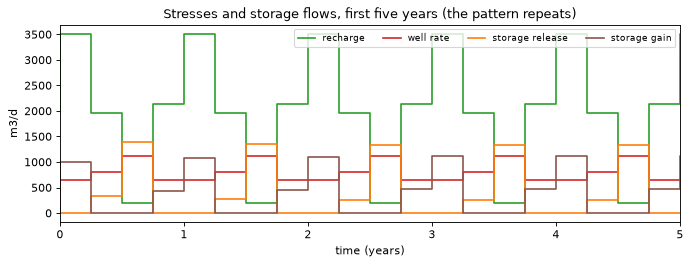

In [2]:
t0 = time.perf_counter()
run = hbd.build_transient(WORK / "model", MF6, n_years=N_YEARS, steps_per_season=STEPS_PER_SEASON)
reader = gs.open_model(run.ws, boundnames=True)
summary = helpers.step_summary(reader, WELL)  # also tutorial 05's snapshot shares, for later
print(f"{len(reader.steps)} time steps over {summary['time (yr)'].iloc[-1]:.1f} years "
      f"(built, run and summarised in {time.perf_counter() - t0:.1f} s)")
print(f"well rate {summary['well rate (m3/d)'].min():.0f} to {summary['well rate (m3/d)'].max():.0f} m3/d; "
      f"recharge {summary['recharge (m3/d)'].iloc[1:].min():.0f} to {summary['recharge (m3/d)'].max():.0f} m3/d")

fig, ax = plt.subplots(figsize=(10.0, 3.2))
for column, colour in (("recharge (m3/d)", "tab:green"), ("well rate (m3/d)", "tab:red"),
                       ("storage release (m3/d)", "tab:orange"), ("storage gain (m3/d)", "tab:brown")):
    ax.step(summary["time (yr)"], summary[column], where="pre", color=colour, label=column.split(" (")[0])
ax.set_xlim(0.0, 5.0)
ax.set_xlabel("time (years)")
ax.set_ylabel("m3/d")
ax.set_title("Stresses and storage flows, first five years (the pattern repeats)")
ax.legend(ncol=4, fontsize=8, loc="upper right")
plt.show()

The aquifer stores water in the wet season and the dry-to-wet transition. It releases water in the wet-to-dry transition and the dry season. In the dry season the well pumps 1120 m³/d while recharge almost stops. The deficit comes out of storage.

## 2. Why snapshots are not transport

Tutorial 05 traced each step on its own, with storage release as a source term. The share of the well's water from each "source" then swings with the seasons:

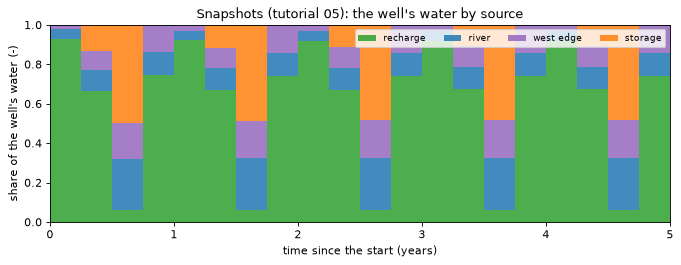

largest snapshot share of storage: 0.50


In [3]:
snapshot = summary.set_index("time (yr)")[["snapshot RCH", "snapshot RIV", "snapshot CHD", "snapshot storage"]]
snapshot.columns = ["recharge", "river", "west edge", "storage"]
fig, ax = plt.subplots(figsize=(10.0, 3.2))
helpers.plot_shares(ax, snapshot, {**COLOURS, "storage": "tab:orange"}, "Snapshots (tutorial 05): the well's water by source")
ax.set_xlim(0.0, 5.0)
ax.legend(loc="upper right", ncol=4, fontsize=8)
plt.show()
print(f"largest snapshot share of storage: {snapshot['storage'].max():.2f}")

In the dry season, about half of the well's water comes "from storage". The snapshot cannot say what that water is. It may be recharge from the last wet season, river water drawn in last year, or water that was already in the aquifer at the start of the simulation. A snapshot also treats every step as if its flow pattern had lasted forever, so the recharge share is high from the very first step, although rain that fell in the first month cannot have reached the well yet.

**Storage is memory.** To answer questions about time, each cell becomes a fully mixed reservoir of water volume $V_i$. Tagged water (a fraction $c_i$ of the cell's water) is carried from step to step. For time step $n$ of length $\Delta t$ (implicit, upstream, no dispersion):

$$
V_i^\text{new}\,c_i^n - V_i^\text{old}\,c_i^{n-1}
= \Delta t \Big[\sum_j q_{ji}\,c_j^n + \sum_{k\in i,\;k\in\text{tagged}} s_k - O_i\,c_i^n\Big]
$$

where $q_{ji}$ are the intercell flows, $s_k$ the tagged source terms (recharge, river leakage, ...) and $O_i$ the cell's total outflow. The storage terms are no longer sources or sinks: they act through the change of volume, $V^\text{old} - V^\text{new} = \Delta t\,S_i$. The volume needs a **porosity**. Section 7 explains how it is used. This is the same equation an MF6 GWT model solves for a unit concentration with upstream advection and no dispersion. Full details are in the docstring of `gwsource.tracking`.

## 3. Forward tracking: tagged sources

`gs.track_forward(reader, sources, config, sinks=...)` runs this scheme over every step. `sources` and `sinks` are dictionaries of `select()` arguments, re-selected on every step. `TrackingConfig.initial_water` adds a tag for the water present at the start (section 4). With every source and the initial water tagged, the fractions sum to 1 in every cell. The tracking runs of sections 3 to 6 split every flow step into four transport sub-steps (`TRANSPORT_SUBSTEPS`), about 23 days each. Section 9 shows why.

forward tracking: 121 steps in 0.46 s, solver topological


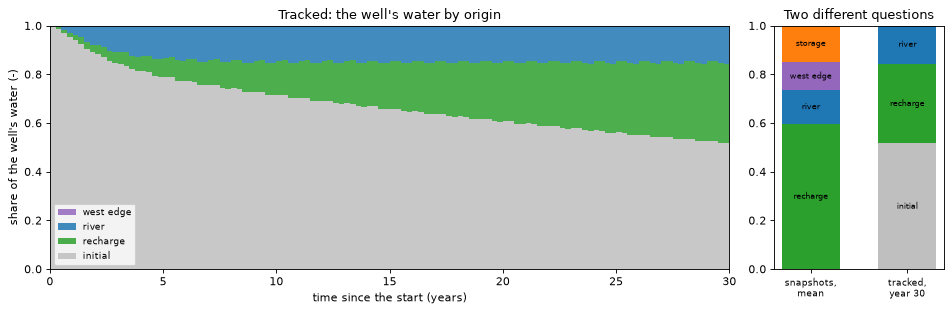

,initial,recharge,river,west edge
end of year,,,,
1,0.954,0.015,0.031,0.0
5,0.790,0.072,0.139,0.0
10,0.714,0.133,0.153,0.0
20,0.605,0.239,0.155,0.0
30,0.516,0.329,0.155,0.0


snapshots, time-weighted mean over the 30 years: {'recharge': 0.6, 'river': 0.14, 'west edge': 0.12, 'storage': 0.15}


In [4]:
config = gs.TrackingConfig(porosity=POROSITY, initial_water={"initial": "all"},
                           substeps=TRANSPORT_SUBSTEPS)  # volume_mode="flow" (default)
t0 = time.perf_counter()
fwd = gs.track_forward(reader, SOURCES, config, sinks=DESTINATIONS)
print(f"forward tracking: {len(fwd.steps)} steps in {time.perf_counter() - t0:.2f} s, solver {fwd.solver_used[0]}")

origin = helpers.origin_shares(fwd, WELL)[["initial", "recharge", "river", "west edge"]]
weights = summary["delt (d)"].iloc[1:].to_numpy()
mean_snapshot = pd.Series({c: np.average(snapshot[c].iloc[1:], weights=weights) for c in snapshot.columns})
fig, (ax, ax_bar) = plt.subplots(1, 2, figsize=(12.0, 4.0), gridspec_kw={"width_ratios": [4.0, 1.0]})
helpers.plot_shares(ax, origin, COLOURS, "Tracked: the well's water by origin")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="lower left", fontsize=8)
bars = {"snapshots,\nmean": mean_snapshot, f"tracked,\nyear {N_YEARS}": origin.iloc[-1]}
colours = {**COLOURS, "storage": "tab:orange"}
for x, (name, shares) in enumerate(bars.items()):
    bottom = 0.0
    for part, share in shares.items():
        ax_bar.bar(x, share, bottom=bottom, color=colours[part], width=0.6)
        if share > 0.04:
            ax_bar.text(x, bottom + share / 2, part, ha="center", va="center", fontsize=7.5)
        bottom += share
ax_bar.set_xticks(range(len(bars)), list(bars), fontsize=8)
ax_bar.set_ylim(0.0, 1.0)
ax_bar.set_title("Two different questions")
fig.tight_layout()
plt.show()
at_years = origin.iloc[helpers.year_steps(fwd.totim, TABLE_YEARS)]
at_years.index = pd.Index(TABLE_YEARS, name="end of year")  # the steps end 1 day later (the steady period)
display(at_years.round(3))
print("snapshots, time-weighted mean over the 30 years:", mean_snapshot.round(2).to_dict())

The tracked answer is very different. In the last season of year 1, 95 % of the pumped water was already in the aquifer at the start ("initial"), 3 % is river water and under 2 % is new recharge. River water arrives first, within months, because the river is 100 m from the well. Recharge builds up slowly. A column of this aquifer (about 38 m saturated, porosity 0.3) holds about 11 m of water. That is 64 years of recharge at 0.18 m/yr. New recharge therefore mixes into a large volume of old water before it reaches the well. After 30 years, half of the pumped water is still older than the start of the simulation. None of it has come from the west edge yet, 1.4 km away.

The snapshot answer (right: 60 % recharge, 15 % storage on average) describes flow paths under each step's flows, not arrival times. If the flows were held constant long enough, the tracked shares would tend to the steady answer. The test suite checks this limit. In this aquifer that would take many decades.

The maps show how the initial water is replaced. Each map shows the fraction of each cell's water that was already there at the start:

cell average at the end: {'recharge': 0.354, 'river': 0.003, 'west edge': 0.074, 'initial': 0.57}


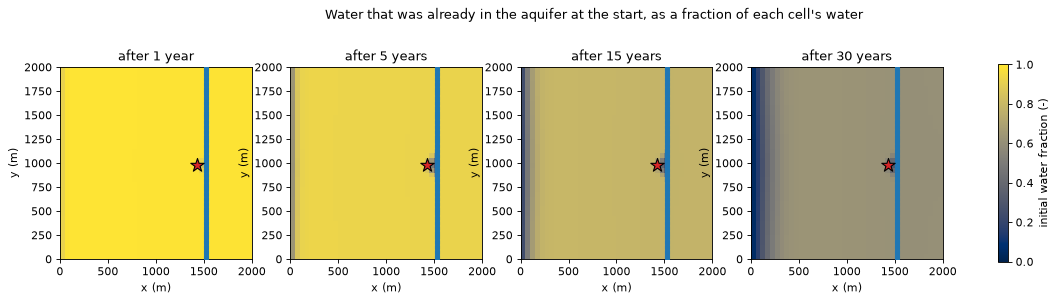

mean saturated thickness 38 m, water column 11.4 m, mean recharge 0.18 m/yr: 64 years of recharge


In [5]:
first = reader.read(reader.steps[0])
active = first.active
panels = [(fwd.source_fraction["initial"][n], f"after {year} year{'s' if year > 1 else ''}")
          for n, year in zip(helpers.year_steps(fwd.totim, MAP_YEARS), MAP_YEARS)]
fig, axes = helpers.map_panels(run.grb_file, first, panels, ncols=4, label="initial water fraction (-)",
                               cmap="cividis", vmin=0.0, vmax=1.0)
fig.suptitle("Water that was already in the aquifer at the start, as a fraction of each cell's water")
n_end = len(fwd.steps) - 1
print("cell average at the end:", {g: round(float(fwd.source_fraction[g][n_end][active].mean()), 3) for g in fwd.groups})
plt.show()

thickness = float(first.saturated_thickness[active].mean())
recharge_per_year = float((summary["recharge (m3/d)"] * summary["delt (d)"]).iloc[1:].sum()
                          / first.area[active].sum() / N_YEARS)
print(f"mean saturated thickness {thickness:.0f} m, water column {POROSITY * thickness:.1f} m, mean recharge "
      f"{recharge_per_year:.2f} m/yr: {POROSITY * thickness / recharge_per_year:.0f} years of recharge")

Recharge replaces the initial water slowly and almost evenly. The model has one layer. Each cell is fully mixed over its whole saturated thickness, so recharge cannot form a young layer on top of old water as it would in a real aquifer. Faster replacement shows up along the west edge, where regional inflow enters, and near the river, where river water is drawn in towards the well. This vertical mixing is a form of numerical dispersion. More layers reduce it. It also spreads the front (see section 9).

## 4. Tagged initial water: how much of the pumped water was already there?

The `"initial"` tag answers this directly: its share of the well's outflow, per step and cumulated over the pumping period. A forward balance per group (`fwd.balance`) closes to round-off.

In [6]:
pumped = pd.DataFrame({g: fwd.outflow_to[WELL][g] for g in fwd.groups}, index=origin.index)  # m3 per step
cumulative = pumped.cumsum()
rows = {}
for n, year in zip(helpers.year_steps(fwd.totim, (1, 2, 5, 10, 20, 30)), (1, 2, 5, 10, 20, 30)):
    that_year = pumped.iloc[n - 3: n + 1].sum()  # the four seasons ending at step n
    rows[f"year {year}"] = {
        "pumped that year (m3)": that_year.sum(),
        "initial water, that year": that_year["initial"] / that_year.sum(),
        "initial water, all pumped so far": cumulative["initial"].iloc[n] / cumulative.iloc[n].sum(),
    }
display(pd.DataFrame(rows).T.round({"pumped that year (m3)": 0, "initial water, that year": 3,
                                    "initial water, all pumped so far": 3}))
balance_errors = {g: gs.tracking.forward_balance_error(fwd, g) for g in fwd.groups}
print("largest relative error of the tagged-water balances:", f"{max(balance_errors.values()):.1e}")

,pumped that year (m3),"initial water, that year","initial water, all pumped so far"
year 1,292200.0,0.976,0.976
year 2,292200.0,0.915,0.945
year 5,292200.0,0.801,0.876
year 10,292200.0,0.721,0.813
year 20,292200.0,0.611,0.736
year 30,292200.0,0.521,0.677


largest relative error of the tagged-water balances: 9.9e-16


Over the first ten years, about four-fifths (81 %) of all pumped water was already in the aquifer at the start of the simulation. When that water differs in quality from the water replacing it, as in a contaminated or a pristine aquifer, this is the number that matters. No snapshot can give it.

## 5. Backward tracking: the adjoint

Forward tracking answers "where is the tagged water at time $t$?" for a few tags. The backward question is the capture question of tutorial 01, now in time: **of the water in each cell at time $t$, what fraction leaves through the well before the end of the simulation?** `gs.track_backward` solves the adjoint of the forward scheme, backward in time from the end:

$$
(\mathbf A^n)^\mathsf T\,\mathbf w^n = \Delta t^n\,\mathbf d^n + \mathbf B^{n+1}\,\mathbf w^{n+1}, \qquad \mathbf w^{N+1} = 0,
$$

where $\mathbf A^n$ is the forward step matrix, $\mathbf B^{n+1}=\mathrm{diag}(V^\text{old})$ of the next step, and $\mathbf d^n$ the well's outflow per cell. $w^n_i$ is the fraction of the water in cell $i$ at the start of step $n$ (or entering it during the step) that leaves through the well before the end. The same run also gives the fraction leaving through **any** sink and the fraction **still stored** at the end. They sum to 1, up to the flow model's own budget residual (in the default `"flow"` volume mode). Section 7 shows the small unaccounted part that `"gwt"` mode adds.

backward tracking: 121 steps in 0.48 s


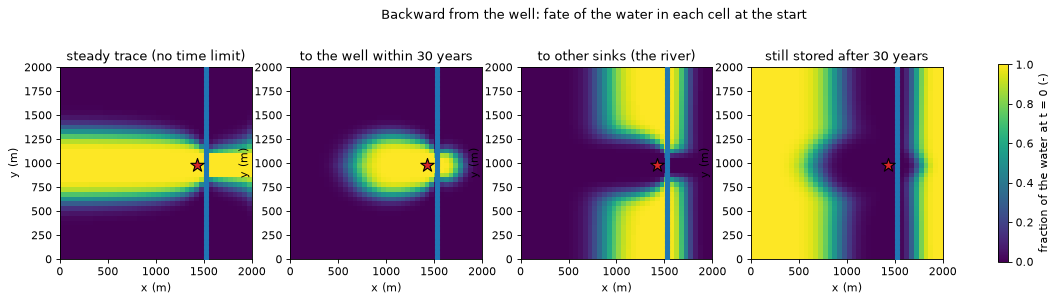

well + other sinks + stored: 1.0000 to 1.0000 over active cells


In [7]:
t0 = time.perf_counter()
bwd = gs.track_backward(reader, DESTINATIONS, config, sources=SOURCES)
print(f"backward tracking: {len(bwd.steps)} steps in {time.perf_counter() - t0:.2f} s")

steady = gs.backward(first, {WELL: gs.select(first, boundnames=[WELL])})  # the steady first step
w0 = bwd.fraction_through[WELL][0]
to_other = bwd.fraction_to_other_sinks(WELL)[0]
stored = bwd.fraction_in_storage_at_end[0]
panels = [
    (steady.fraction_through[WELL], "steady trace (no time limit)"),
    (w0, f"to the well within {N_YEARS} years"),
    (to_other, "to other sinks (the river)"),
    (stored, f"still stored after {N_YEARS} years"),
]
fig, axes = helpers.map_panels(run.grb_file, first, panels, ncols=4, label="fraction of the water at t = 0 (-)",
                               cmap="viridis", vmin=0.0, vmax=1.0)
fig.suptitle("Backward from the well: fate of the water in each cell at the start")
plt.show()
total = w0 + to_other + stored
print(f"well + other sinks + stored: {total[active].min():.4f} to {total[active].max():.4f} over active cells")

The steady trace (left, tutorial 01's $F$) says which water reaches the well *eventually*. The transient adjoint adds the time limit. Within 30 years, only the water near the well and along the main flow paths reaches it. Most of the capture zone's water is still on its way at the end (right). The river drains much of the water east of the well and near the river (third panel).

The three fractions sum to 1 up to the flow model's budget residual. In `"gwt"` volume mode they would miss by a few parts in a thousand (section 7).

### Closure: the well's water split by source and initial water

With every source tagged, the adjoint splits the well's total outflow over 30 years into the water that entered through each source term (`volume_from_by_package`) and the initial water (`initial_volume_from`). The parts add up to the well's outflow.

In [8]:
closure = gs.tracking.backward_closure(bwd, WELL)
parts = {p: float(v.sum()) for p, v in bwd.volume_from_by_package[WELL].items() if v.sum() > 1e-6 * closure.rhs}
parts["initial water"] = float(bwd.initial_volume_from[WELL].sum())
table = pd.Series(parts, name="volume (m3)").to_frame()
table["share"] = table["volume (m3)"] / closure.rhs
display(table.round({"volume (m3)": 0, "share": 3}))
print(f"sum of parts {closure.lhs:,.0f} m3 = well outflow {closure.rhs:,.0f} m3 "
      f"(relative error {closure.relative_error:.1e})")

,volume (m3),share
RIV,1210520.0,0.138
RCH,1620248.0,0.185
initial water,5936032.0,0.677


sum of parts 8,766,800 m3 = well outflow 8,766,800 m3 (relative error 0.0e+00)


## 6. Duality: forward and backward give the same numbers

Forward tracking computes the tagged water leaving through the well, step by step. The adjoint computes the same quantity as an inner product of the tagged inputs with $\mathbf w$:

$$
\sum_n \Delta t^n\, \mathbf d^n\cdot\mathbf c^n \;=\; \sum_n \Delta t^n\, \mathbf s^n\cdot\mathbf w^n \;+\; \mathbf V^{\text{old},1}\mathbf c^0\cdot\mathbf w^1 .
$$

The identity is exact for the discrete scheme, whatever the volumes and flows. It checks that the forward and backward codes solve the same discrete problem. It does not check the flow model or the full-mixing assumption. `gs.tracking_duality` compares the two sides for one source and one destination:

In [9]:
rows = {}
for source in [*SOURCES, "initial"]:
    check = gs.tracking_duality(fwd, source, bwd, WELL)
    rows[source] = {"forward (m3)": check.rhs, "adjoint (m3)": check.lhs, "relative difference": check.relative_error}
duality = pd.DataFrame(rows).T
display(duality.round({"forward (m3)": 1, "adjoint (m3)": 1}))
assert duality["relative difference"].max() < 1e-10

,forward (m3),adjoint (m3),relative difference
recharge,1620248.3,1620248.3,4.311018e-16
river,1210519.6,1210519.6,0.000000e+00
west edge,0.0,0.0,3.915830e-16
initial,5936032.1,5936032.1,3.137862e-16


The two sides agree to round-off. The duality lets you choose the cheaper direction. One backward run gives the well's catchment for every cell and every start time. One forward run gives the spread of one tagged source to every sink.

## 7. Volume modes: "gwt" and "flow"

The volumes $V^\text{old}$ and $V^\text{new}$ need a porosity. The flow model's storage change is set by its own specific yield. When the two differ (here porosity 0.3, specific yield 0.2), the volumes cannot follow both. `TrackingConfig.volume_mode` chooses:

- **`"gwt"`** does what MF6 GWT does. At the end of each step, $V^\text{new}$ = porosity × saturated volume. $V^\text{old} = V^\text{new} + \Delta t\,S$ follows from the step's storage flow. Within a step the water balance closes. Between steps, however, the volume at the start of step $n+1$ is not the volume at the end of step $n$. When the water table falls by $\Delta h$, the flow model releases $S_y A \Delta h$ but the porosity volume falls by $\phi A \Delta h$. The difference $(S_y-\phi) A\Delta h$ of water, with its tags, appears or disappears at the step boundary. `gwsource` reports it as the `volume_adjustment` of the balance. It also makes adjoint fractions slightly above 1 possible.
- **`"flow"` (default)** carries the volume with the storage flows. The volume starts at porosity × saturated volume, then $V^{\text{old},n+1} = V^{\text{new},n}$ and $V^\text{new} = V^\text{old} - \Delta t\,S$. Water and tagged-water balances are exact. Porosity only sets the starting volume, so the volume can drift away from porosity × saturated volume.

Neither is more correct. They are different idealisations of an unconfined aquifer whose drainable and mobile pore space differ. `gwsource` defaults to `"flow"` because exact water balances make every closure and fate map add up. Use `"gwt"` to compare with an MF6 GWT model. The cell below runs the forward and backward tracking of sections 3 to 5 in both modes and compares them. Both runs use one transport step per flow step, as the MF6 GWT model of section 8 does.

In [10]:
config_flow1 = gs.TrackingConfig(porosity=POROSITY, initial_water={"initial": "all"})  # substeps=1
config_gwt = gs.TrackingConfig(porosity=POROSITY, initial_water={"initial": "all"}, volume_mode="gwt")
fwd_flow1 = gs.track_forward(reader, SOURCES, config_flow1, sinks=DESTINATIONS)
bwd_flow1 = gs.track_backward(reader, DESTINATIONS, config_flow1, sources=SOURCES)
fwd_gwt = gs.track_forward(reader, SOURCES, config_gwt, sinks=DESTINATIONS)
bwd_gwt = gs.track_backward(reader, DESTINATIONS, config_gwt, sources=SOURCES)

rows = {}
for name, f, b in (("flow (default)", fwd_flow1, bwd_flow1), ("gwt", fwd_gwt, bwd_gwt)):
    rows[name] = {
        "initial water lost or gained at step boundaries (m3)": float(f.balance["initial"]["volume_adjustment"].sum()),
        "initial water at the start (m3)": float(f.balance["initial"]["storage_start"][0]),
        "largest volume jump at a step boundary (m3)": float(f.volume_jump.max()),
        "largest adjoint fraction to the well": float(np.nanmax(b.fraction_through[WELL])),
        "largest |unaccounted fraction|": float(np.nanmax(np.abs(b.fraction_unaccounted))),
        "well water that is initial, year 30": float(helpers.origin_shares(f, WELL)["initial"].iloc[-1]),
    }
display(pd.DataFrame(rows).map(lambda v: f"{v:.4g}"))
diff_c = max(np.abs(fwd_gwt.source_fraction[g] - fwd_flow1.source_fraction[g])[:, active].max() for g in fwd.groups)
diff_w = np.abs(bwd_gwt.fraction_through[WELL] - bwd_flow1.fraction_through[WELL])[:, active].max()
print(f"largest difference between the modes: {diff_c:.1e} in c, {diff_w:.1e} in w (any cell, any step)")

,flow (default),gwt
initial water lost or gained at step boundaries (m3),0,-5290
initial water at the start (m3),4.555e+07,4.555e+07
largest volume jump at a step boundary (m3),0,321.2
largest adjoint fraction to the well,1,1.004
largest |unaccounted fraction|,2.625e-11,0.004248
"well water that is initial, year 30",0.5166,0.5167


largest difference between the modes: 1.9e-04 in c, 3.7e-03 in w (any cell, any step)


For this model the modes differ by up to $1.9 \times 10^{-4}$ in the forward fractions and $3.7 \times 10^{-3}$ in the adjoint fractions. In gwt mode, about 5,300 m³ of the 45.6 million m³ of initial water is destroyed at step boundaries over 30 years. The adjoint fractions exceed 1 by up to 0.4 %. The unaccounted part of the fate maps is of the same size. The well's mix hardly changes: half of its water in year 30 is initial water in both modes. In flow mode those artefacts vanish, up to the flow model's own residual. The difference grows with the seasonal water-table swing and with $|S_y - \phi|$. Check it on your model when the answer is close to a decision threshold.

## 8. Comparison with MF6 GWT

To check the scheme against an independent code, `hbd.run_gwt_tracer` builds an MF6 GWT model that reads the flow model's heads and budgets (FMI). It uses upstream advection, no dispersion, MST porosity 0.3, `FLOW_IMBALANCE_CORRECTION`, concentration 1 on every recharge bound and 0 elsewhere. The GWT concentration is then the tracked recharge fraction. The gwt-mode run of section 7 (`fwd_gwt`) should reproduce it at every step. The comparison covers the recharge tag, with `volume_mode="gwt"` and one transport step per flow step.

GWT run in 2.0 s
max |c(gwsource) - C(GWT)| over 1600 cells and 121 steps: 9.8e-14
with the default flow volumes instead: max |c(gwsource) - C(GWT)| = 1.7e-04


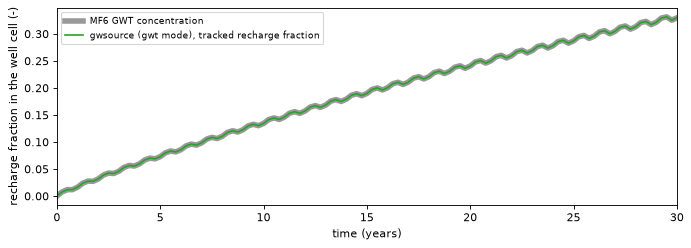

In [11]:
t0 = time.perf_counter()
ucn_file = hbd.run_gwt_tracer(run, WORK / "gwt", MF6, POROSITY, tagged=("rch",))
ucn = flopy.utils.HeadFile(str(ucn_file), text="CONCENTRATION")
gwt_c = np.array([np.asarray(ucn.get_data(kstpkper=ks), float).ravel() for ks in fwd.steps])
print(f"GWT run in {time.perf_counter() - t0:.1f} s")
error = np.abs(gwt_c[:, active] - fwd_gwt.source_fraction["recharge"][:, active])
print(f"max |c(gwsource) - C(GWT)| over {active.sum()} cells and {len(fwd.steps)} steps: {error.max():.1e}")
assert error.max() < 1e-8
error_flow = np.abs(gwt_c[:, active] - fwd_flow1.source_fraction["recharge"][:, active])
print(f"with the default flow volumes instead: max |c(gwsource) - C(GWT)| = {error_flow.max():.1e}")

well_cell = run.info["well_nodes"][WELL]
fig, ax = plt.subplots(figsize=(10.0, 3.2))
years = fwd.totim / helpers.DAYS_PER_YEAR
ax.plot(years, gwt_c[:, well_cell], color="0.6", lw=5, label="MF6 GWT concentration")
ax.plot(years, fwd_gwt.source_fraction["recharge"][:, well_cell], color="tab:green", lw=1.5,
        label="gwsource (gwt mode), tracked recharge fraction")
ax.set_xlabel("time (years)")
ax.set_ylabel("recharge fraction in the well cell (-)")
ax.set_xlim(0.0, N_YEARS)
ax.legend(fontsize=8)
plt.show()

The two agree to round-off ($\sim 10^{-13}$) in every cell at every step. With the default `"flow"` volumes, the recharge fractions differ from GWT by up to $1.7 \times 10^{-4}$. Over all tags, the two volume modes differ by up to $1.9 \times 10^{-4}$ (section 7). The test suite runs the same comparison for river and constant-head tags, tagged initial water, the case without flow-error correction, and a stream network (SFR + MVR) against GWT with SFT and MVT. In gwt mode with one transport step per flow step, the scheme is GWT's upstream, dispersion-free unit-concentration transport. It is reorganised so that the backward (adjoint) problem and many tags come at the same cost.

## 9. Sub-steps and early arrival

Implicit time stepping lets tagged water cross many cells within one long step, which adds numerical dispersion in time: early arrivals come too early. `TrackingConfig.substeps = m` splits every flow step into $m$ equal transport sub-steps (flows constant, volumes interpolated) without touching the flow model. The duality and closure stay exact. Here the flow steps are about 91 days long:

flow steps: 91.3 days on average


substeps =  1 ( 91.3-day transport steps): 0.18 s


substeps =  4 ( 22.8-day transport steps): 0.36 s


substeps = 16 (  5.7-day transport steps): 1.06 s


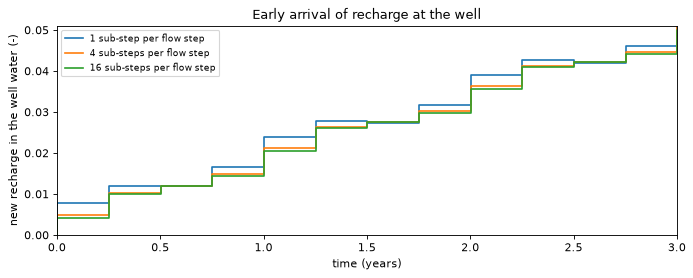

,m = 1,m = 4,m = 16
first year,,,
step 1,0.0078,0.0049,0.0042
step 2,0.0118,0.0104,0.0100
step 3,0.0119,0.0120,0.0120
step 4,0.0165,0.0149,0.0145


first step: m = 1 over m = 16: 1.85; m = 4 over m = 16: 1.17


In [12]:
flow_step = float(summary["delt (d)"].iloc[1:].mean())  # days per seasonal flow step
print(f"flow steps: {flow_step:.1f} days on average")
runs = {}
for m in SUBSTEPS:
    t0 = time.perf_counter()
    config_m = gs.TrackingConfig(porosity=POROSITY, substeps=m, keep_series=True)
    tracked = gs.track_forward(reader, {"recharge": SOURCES["recharge"]}, config_m, sinks=DESTINATIONS)
    rate = summary["well rate (m3/d)"].to_numpy() * summary["delt (d)"].to_numpy()
    runs[m] = pd.Series(tracked.outflow_to[WELL]["recharge"] / rate, index=years)
    print(f"substeps = {m:2d} ({flow_step / m:5.1f}-day transport steps): {time.perf_counter() - t0:.2f} s")

fig, ax = plt.subplots(figsize=(10.0, 3.4))
for m, series in runs.items():
    ax.step(series.index, series, where="pre", label=f"{m} sub-step{'s' if m > 1 else ''} per flow step")
ax.set_xlim(0.0, 3.0)
ax.set_ylim(0.0, 1.2 * max(float(s[s.index <= 3.0].max()) for s in runs.values()))
ax.set_xlabel("time (years)")
ax.set_ylabel("new recharge in the well water (-)")
ax.set_title("Early arrival of recharge at the well")
ax.legend(fontsize=8)
plt.show()
early = pd.DataFrame({f"m = {m}": s.iloc[1:5].to_numpy() for m, s in runs.items()},
                     index=pd.Index([f"step {n}" for n in range(1, 5)], name="first year"))
display(early.round(4))
print(f"first step: m = 1 over m = {SUBSTEPS[-1]}: {early.iloc[0, 0] / early.iloc[0, -1]:.2f}; "
      f"m = {SUBSTEPS[1]} over m = {SUBSTEPS[-1]}: {early.iloc[0, 1] / early.iloc[0, -1]:.2f}")

With one transport step per 91-day flow step, the share of new recharge in the first step is 1.85 times the 16-sub-step value. With four sub-steps it is 1.17 times that value. Sixteen sub-steps change the curve only slightly more than four. This is why sections 3 to 6 use four sub-steps. Later in the record the curves merge: time stepping changes the spread of the arrivals, not their mean. As a rule of thumb, keep the transport step a small fraction of the time window you read arrivals over. Refine it with `substeps` rather than by refining the flow model.

In [13]:
print(f"notebook runtime: {time.perf_counter() - T_START:.0f} s")

notebook runtime: 10 s


## Key points

- Snapshots (tutorial 05) treat storage as a source with no history. They describe each step's flow pattern, not the age or origin of the water. True transient tracking carries tagged water through storage: **storage is memory**.
- `gs.track_forward` gives the tagged fraction in every cell and in every sink's outflow over time. With `initial_water` it answers "how much of the pumped water was already there?" Here that is 81 % over the first ten years.
- `gs.track_backward` (the adjoint) gives, for the water in each cell at each time, the fraction that leaves through the destination, through any other sink, or is still stored at the end. With all sources tagged it splits the destination's outflow by source and initial water. The parts add up exactly.
- Forward and backward runs satisfy an exact duality (`gs.tracking_duality`), here to about $10^{-16}$.
- The default `volume_mode="flow"` keeps exact water balances. `volume_mode="gwt"` reproduces MF6 GWT to round-off. When porosity ≠ specific yield, it creates or destroys a little tagged water at step boundaries. Here the modes differ by up to $1.9 \times 10^{-4}$ in $c$ and $3.7 \times 10^{-3}$ in $w$.
- Long flow steps make early arrivals too early. Use `substeps` (four in this tutorial, see section 9).
- Requirements: every time step saved in the budget file, and a porosity. Tracking also works on multi-model simulations and package networks (tutorial 07) through `gs.open_simulation`.

## Next

[09 · Ensembles](../09_ensembles/09_ensembles.ipynb): how certain is the capture zone? Capture probability across random-K realisations, quantiles, parallel runs, and how this plugs into a PEST++ IES workflow.